# 05. Benchmarks: M4, M3 e Rdatasets

Os dados oficiais são baixados **uma vez**, quando você pede, para o cache local (`~/.cache/autohybts/datasets` ou a variável `AUTOHYBTS_DATA_DIR`), com checksum SHA-256 e manifesto de origem e licença. Nada é baixado na instalação ou no `import`; com `offline=True`, só o cache é usado.

O teste oficial de cada série entra no experimento como **teste selado**: a busca e a seleção nunca o veem.

Isto **não** reproduz o score oficial das competições: é a avaliação de séries individuais.

In [1]:
import autohybts

print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc2


## 1. Catálogo

In [2]:
from autohybts.datasets import list_datasets, load_benchmark

list_datasets()

,provider,kind,license
0,synthetic,séries sintéticas offline,MIT
1,m5,não suportado (sem WRMSSE oficial),NaN
2,m4,benchmark M4 (treino/teste oficiais),Dados da competição M4 (Makridakis et al.); ve...
3,m3,benchmark M3 (treino/teste oficiais),GPL-3 (pacote R Mcomp); dados da competição M3...
4,rdatasets,catálogo Rdatasets (colunas e tempo explícitos),Varia por pacote R de origem; consulte a docum...


In [3]:
list_datasets(provider="m4", subset="daily").head()

,series_id,subset,category,horizon,seasonal_period,starting_date
0,D1,daily,Macro,14,1,03-01-94 12:00
1,D2,daily,Macro,14,1,02-01-95 12:00
2,D3,daily,Macro,14,1,05-01-06 12:00
3,D4,daily,Macro,14,1,30-05-96 12:00
4,D5,daily,Macro,14,1,03-01-97 12:00


## 2. Uma série do M4 com o teste oficial selado

`series.full()` junta treino e teste oficial; `test_size=len(series.test)` sela exatamente o teste oficial.

In [4]:
series = load_benchmark("m4", subset="daily", series_id="D1")
series, series.descriptor.horizon, series.descriptor.license

(BenchmarkSeries(m4:D1, treino=1006, teste=14, freq=daily),
 14,
 'Dados da competição M4 (Makridakis et al.); ver o repositório M4-methods')

In [5]:
from autohybts import AutoHybridExperiment

exp = AutoHybridExperiment(
    fh=series.descriptor.horizon,
    test_size=len(series.test),
    seasonal_period=7,
    session_id=42,
    base_models=["naive", "seasonal_naive", "linear", "knn"],
    correctors=["linear"],
).fit(series.full())
result = exp.compare_models()
result.decisions[["family", "champion_before", "challenger", "accepted", "median_gain", "win_rate"]]

,family,champion_before,challenger,accepted,median_gain,win_rate
0,statistical,linear,naive,False,0.043331,0.571429
1,kernel,linear,knn,False,-0.109782,0.428571
2,residual,linear,linear-linear,False,-0.001741,0.428571


## 3. Avaliação no teste oficial (uma vez)

In [6]:
final = exp.finalize_model(result.best)
external = exp.evaluate_external(final)
external.metrics

,MASE,MAE,RMSE,sMAPE
model,,,,
linear(lags=7),1.665311,21.92993,23.684067,0.010677


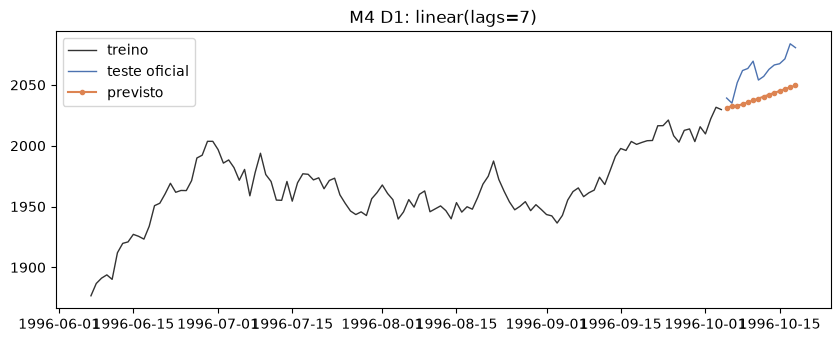

In [7]:
import matplotlib.pyplot as plt

train = series.train.iloc[-120:]
predictions = external.predictions
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(train.index, train.to_numpy(), color="#333333", linewidth=1, label="treino")
ax.plot(
    predictions.index, predictions["y_true"], color="#4C72B0", linewidth=1, label="teste oficial"
)
ax.plot(
    predictions.index, predictions["y_pred"], "o-", color="#DD8452", markersize=3, label="previsto"
)
ax.set_title(f"M4 D1: {final.spec.label}")
ax.legend()
plt.show()

## 4. M3

O M3 vem do pacote R `Mcomp` (CRAN). Ler o arquivo R requer o extra `datasets` (`pip install "autohybts[datasets]"`). Na primeira vez a conversão leva alguns segundos; depois o cache em CSV é usado.

In [8]:
m3 = load_benchmark("m3", subset="monthly", series_id="N1402")
m3

BenchmarkSeries(m3:N1402, treino=50, teste=18, freq=monthly)

Um painel com as três séries mensais mais longas do M3 (muitas têm só 48 pontos), cada uma com seu teste oficial selado:

In [9]:
monthly = load_benchmark("m3", subset="monthly")
ids = list(monthly.metadata.sort_values("n_train").index[-3:])
panel = monthly.panel(ids)
exp_m3 = AutoHybridExperiment(
    fh=monthly.descriptor.horizon,
    test_size=monthly.descriptor.horizon,
    fold=1,
    budget="smoke",
    base_models=["naive", "seasonal_naive", "linear"],
    correctors=["linear"],
).fit(panel)
result_m3 = exp_m3.compare_models()
model_m3 = exp_m3.finalize_model(result_m3.best)
external_m3 = exp_m3.evaluate_external(model_m3)
external_m3.metrics

MASE         MAE        RMSE     sMAPE
model           series_id                                            
linear(lags=12) N2076      0.941339  157.583490  197.962067  0.043483
                N2077      0.229650  126.438669  170.732053  0.036258
                N2031      0.736340  331.934242  464.550832  0.089966
                média      0.635776  205.318800  277.748317  0.056569

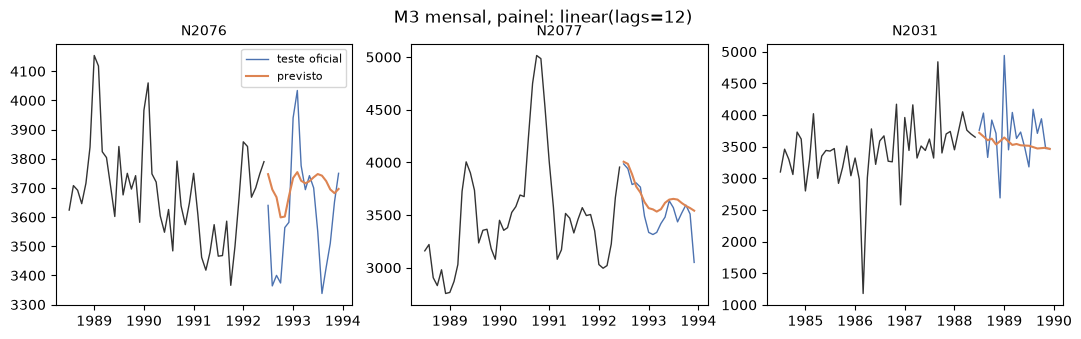

In [10]:
h = monthly.descriptor.horizon
fig, axes = plt.subplots(1, len(ids), figsize=(13, 3.4))
for k, (ax, sid) in enumerate(zip(axes, model_m3.models, strict=True)):
    part = external_m3.predictions.iloc[k * h : (k + 1) * h]
    frame = panel[sid]
    ax.plot(
        frame.timestamps[-h - 48 : -h], frame.values[-h - 48 : -h], color="#333333", linewidth=1
    )
    ax.plot(part.index, part["y_true"], color="#4C72B0", linewidth=1, label="teste oficial")
    ax.plot(part.index, part["y_pred"], color="#DD8452", label="previsto")
    ax.set_title(sid, fontsize=10)
axes[0].legend(fontsize=8)
fig.suptitle(f"M3 mensal, painel: {model_m3.spec.label}")
plt.show()

## 5. Rdatasets

O Rdatasets é um catálogo heterogêneo: tempo, alvo e frequência são escolhidos explicitamente. `raw_dataset` mostra a tabela como publicada.

In [11]:
from autohybts.datasets import load_dataset, raw_dataset

raw_dataset("rdatasets", package="datasets", name="AirPassengers").head()

,rownames,time,value
0,1,1949.000000,112
1,2,1949.083333,118
2,3,1949.166667,132
3,4,1949.250000,129
4,5,1949.333333,121


In [12]:
air = load_dataset(
    "rdatasets",
    package="datasets",
    name="AirPassengers",
    target="value",
    time_col="time",
    frequency="MS",
)
air.train.tail()

1960-08-01    606.0
1960-09-01    508.0
1960-10-01    461.0
1960-11-01    390.0
1960-12-01    432.0
Freq: MS, Name: AirPassengers, dtype: float64

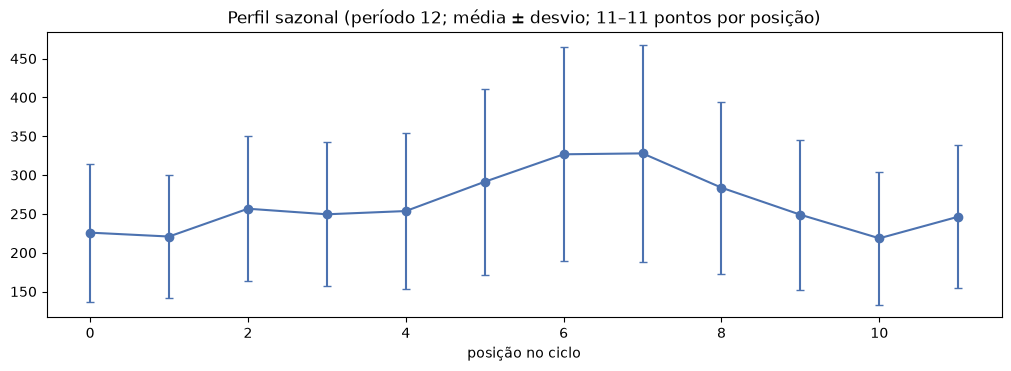

In [13]:
air_exp = AutoHybridExperiment(fh=12, fold=3).fit(air.full())
air_exp.plot_data("seasonality")  # média ± desvio por mês